In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
folder = Path('230915_all_conditions_decon')

# Load all individual files about mito distance to MTOC

In [9]:
mito_info = pd.DataFrame()
for file in folder.glob('*mito_info.csv'):
    file_split = file.stem.split('_')
    df = pd.read_csv(file)
    df['condition'] = ' '.join(file_split[1:-4])
    mito_info = pd.concat([mito_info, df])

mito_info.to_csv(folder / 'all_mito_info.csv', index=False)
    

In [10]:
mito_info = pd.read_csv(folder / 'all_mito_info.csv')

## Filter by condition
But for the plot we only need wt

In [12]:
for item in mito_info.condition.unique():
    print(item)

si control
si TRAK1
si TRAK2
wt
galactose 48h
galactose ON
TRAK1 oe
TRAK2 oe


In [13]:
#condition filtering
condition = 'wt'
voxel_size = 0.00121

mito_info_filtered = mito_info[mito_info.condition == condition].copy()
mito_info_filtered['size (µm³)'] = mito_info_filtered['size'] * voxel_size
mito_info_filtered_big = mito_info_filtered[mito_info_filtered['size (µm³)'] > 2]

In [14]:
mito_info_filtered.head()

,file,mito,size,distance,condition,size (µm³)
17932,S4_wt_001_mitosurface,0,2272,20.636150,wt,2.74912
17933,S4_wt_001_mitosurface,1,11232,7.403237,wt,13.59072
17934,S4_wt_001_mitosurface,2,1004,6.877449,wt,1.21484
17935,S4_wt_001_mitosurface,3,3984,8.741080,wt,4.82064
17936,S4_wt_001_mitosurface,4,2484,3.144400,wt,3.00564


In [15]:
distances = mito_info_filtered_big['distance']
sizes = mito_info_filtered_big['size']
median_big = mito_info_filtered_big['distance'].median()

poly1d_fn = np.poly1d(np.polyfit(distances, sizes, 1))

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

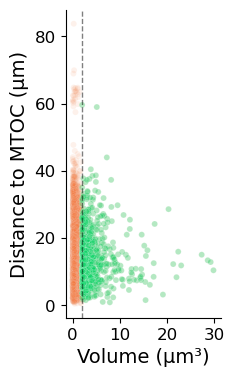

In [17]:
fig, ax = plt.subplots(figsize=(2,4))

sns.scatterplot(data=mito_info_filtered, y='distance', x='size (µm³)', alpha=0.1, legend=False, size=2, color='#F27B40')
sns.scatterplot(data=mito_info_filtered_big, y='distance', x='size (µm³)', alpha=0.3, legend=False, size=2, color='#0BD566')
ax.axvline(x=2, color='black', linestyle='--', linewidth=1, alpha=0.5)
#ax.axhline(y=median_big, color='black', linestyle='--', linewidth=1, alpha=0.5)
#ax.plot(distances, poly1d_fn(distances), '--k')

plt.ylabel('Distance to MTOC (µm)', fontsize=14)
plt.xticks([0, 10, 20, 30], fontsize=12)
plt.xlabel('Volume (µm³)', fontsize=14)
plt.yticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('paper_plots/distance_size_wt.png', dpi=300, bbox_inches='tight')